# ¿En qué se me va el dinero?
### Análisis exploratorio de mis gastos personales

**Autora:** María Isabel Ruíz Machorro · **Herramientas:** Python, pandas, matplotlib y seaborn

Este reporte analiza los movimientos (gastos e ingresos) que registro en mi app de finanzas personales. Quiero responder cinco preguntas:

1. **¿Cuánto gasto y cuánto me queda cada mes?**
2. **¿En qué categorías se concentra el gasto?**
3. **¿Gasto distinto según el día de la semana?**
4. **¿Qué gastos son fijos (recurrentes) y cuáles salen de lo normal (atípicos)?**
5. **¿Cuánto debería esperar gastar el próximo mes?**

El proceso sigue las etapas clásicas de la minería de datos: **obtener → limpiar → explorar → modelar → concluir**. Cada sección explica qué se hace, por qué, y termina con un recuadro de *Hallazgo* calculado a partir de los propios datos.

> **Sobre los datos.** Por privacidad, la versión pública de este reporte usa **datos de ejemplo inventados** (`data/ejemplo/movimientos_ejemplo.csv`), generados con `generar_datos_ejemplo.py` para imitar a una estudiante en México. El mismo notebook funciona con mis datos reales cambiando una sola variable (`FUENTE`), porque ambos archivos tienen las mismas columnas.

## 0. Preparación

Se cargan las librerías y se define un estilo común para todas las gráficas: fondo claro, cuadrícula discreta y una paleta de colores comprobada para personas con daltonismo. También se definen tres ayudantes pequeños:

- `pesos()` da formato de moneda (`$1,234`),
- `etiqueta_mes()` abrevia un mes (`ago 26`),
- `hallazgo()` muestra las conclusiones de cada sección en un recuadro.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

# ── Fuente de datos: "ejemplo" (inventados, públicos) o "real" (mis datos, privados) ──
FUENTE = "ejemplo"
RUTAS = {
    "ejemplo": Path("data/ejemplo/movimientos_ejemplo.csv"),
    "real": Path("data/movimientos.csv"),  # lo crea exportar_datos.py; git lo ignora
}

# ── Colores ──
AZUL, NARANJA = "#2a78d6", "#eb6834"        # series 1 y 2 de la paleta
FONDO, TINTA, TINTA_2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE = "#e1e0d9", "#c3c2b7"
ESCALA_AZUL = LinearSegmentedColormap.from_list("azul", ["#eef4fd", "#9ec5f4", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "figure.dpi": 110, "font.size": 10.5,
    "text.color": TINTA, "axes.labelcolor": TINTA_2,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.edgecolor": EJE, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 14,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def pesos(valor, decimales=0):
    # 1234.5 -> '$1,235'  (el signo menos va antes del $)
    return f"{'−' if valor < 0 else ''}${abs(valor):,.{decimales}f}"


def etiqueta_mes(periodo):
    # Period('2026-08') -> 'ago 26'
    return f"{MESES[periodo.month - 1]} {str(periodo.year)[2:]}"


def hallazgo(texto):
    display(Markdown("> **Hallazgo.** " + texto.strip().replace("\n", "\n> ")))


EJE_PESOS = FuncFormatter(lambda v, _: pesos(v))
print("Fuente de datos:", FUENTE, "->", RUTAS[FUENTE])

Fuente de datos: ejemplo -> data/ejemplo/movimientos_ejemplo.csv


## 1. Obtención de los datos

Los movimientos viven en una base de datos PostgreSQL (Supabase). El script `exportar_datos.py` inicia sesión con mi usuario y los descarga a un CSV. Cada fila es **un movimiento** con siete columnas:

| Columna | Significado |
|---|---|
| `fecha` | Día del movimiento |
| `tipo` | `gasto` o `ingreso` |
| `monto` | Cantidad en pesos mexicanos (siempre positiva; el signo lo da `tipo`) |
| `categoria` | Categoría asignada en la app |
| `descripcion` | Texto libre o descripción del banco |
| `metodo_pago` | `efectivo`, `debito`, `credito` o `transferencia` |
| `origen` | `manual` (capturado a mano) o `banco` (importado del estado de cuenta) |

Se lee todo como texto (`dtype=str`) a propósito: así ningún valor se convierte en silencio y la limpieza decide, paso por paso, qué es válido.

In [2]:
crudo = pd.read_csv(RUTAS[FUENTE], dtype=str, keep_default_na=False)
print(f"{len(crudo):,} filas y {crudo.shape[1]} columnas")
crudo.head()

630 filas y 7 columnas


,fecha,tipo,monto,categoria,descripcion,metodo_pago,origen
0,2026-01-01,ingreso,5500.00,Beca / Mesada,Beca mensual,transferencia,banco
1,2026-01-01,gasto,45.00,Comida,Café,efectivo,manual
2,2026-01-02,gasto,170.50,Comida,Pizza,efectivo,manual
3,2026-01-02,gasto,86.00,Transporte,UBER TRIP,debito,banco
4,2026-01-03,gasto,49.00,Comida,Torta,efectivo,manual


## 2. Limpieza

Los datos reales nunca llegan perfectos, y un análisis sobre datos sucios da conclusiones equivocadas. Antes de limpiar conviene **medir** los problemas, para saber qué se corrige y cuánto pesa.

In [3]:
diagnostico = pd.Series({
    "Filas totales": len(crudo),
    "Fechas que no se pueden interpretar": pd.to_datetime(crudo["fecha"], errors="coerce").isna().sum(),
    "Montos no numéricos o no positivos": (~(pd.to_numeric(crudo["monto"], errors="coerce") > 0)).sum(),
    "Tipos distintos de gasto/ingreso": (~crudo["tipo"].isin(["gasto", "ingreso"])).sum(),
    "Descripciones vacías": (crudo["descripcion"].str.strip() == "").sum(),
    "Formas distintas de escribir las categorías": crudo["categoria"].nunique(),
    "Categorías reales (ignorando mayúsculas y espacios)": crudo["categoria"].str.strip().str.casefold().nunique(),
    "Filas repetidas exactamente": crudo.duplicated().sum(),
}, name="cantidad")
diagnostico.to_frame()

,cantidad
Filas totales,630
Fechas que no se pueden interpretar,0
Montos no numéricos o no positivos,0
Tipos distintos de gasto/ingreso,0
Descripciones vacías,12
Formas distintas de escribir las categorías,16
Categorías reales (ignorando mayúsculas y espacios),13
Filas repetidas exactamente,1


Con el diagnóstico a la vista, la limpieza se hace en cinco pasos:

1. **Tipos de dato.** `fecha` pasa a fecha y `monto` a número. Lo que no se pueda convertir, o tenga un tipo o monto inválido, se descarta (y se cuenta).
2. **Categorías unificadas.** `"comida"`, `" Comida"` y `"COMIDA "` son la misma categoría. Se agrupan ignorando mayúsculas y espacios, y se conserva la forma de escribirla más frecuente.
3. **Descripciones vacías.** No se eliminan (el monto sigue siendo válido): se rellenan con `"Sin descripción"`.
4. **Duplicados exactos.** Una fila idéntica en todas sus columnas casi siempre es un error de captura o de importación, así que se conserva solo una. *Es una decisión con riesgo:* dos compras reales idénticas el mismo día se perderían; por eso se muestran antes de quitarlas.
5. **Columnas derivadas.** Se agregan `mes`, `dia_semana` y `fin_de_semana`, que se usan en el resto del análisis.

In [4]:
df = crudo.copy()

# 1) Tipos de dato
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
df["monto"] = pd.to_numeric(df["monto"], errors="coerce")
validas = df["fecha"].notna() & (df["monto"] > 0) & df["tipo"].isin(["gasto", "ingreso"])
descartadas = int((~validas).sum())
df = df[validas].copy()

# 2) Categorías unificadas: la forma más frecuente de cada una
df["categoria"] = df["categoria"].str.strip().replace("", "Sin categoría")
clave = df["categoria"].str.casefold()
forma_canonica = df.groupby(clave)["categoria"].agg(lambda s: s.value_counts().idxmax())
df["categoria"] = clave.map(forma_canonica)

# 3) Descripciones vacías
df["descripcion"] = df["descripcion"].str.strip().replace("", "Sin descripción")

# 4) Duplicados exactos (se muestran antes de quitarlos)
repetidas = df[df.duplicated(keep=False)]
duplicados = int(df.duplicated().sum())
df = df.drop_duplicates().sort_values("fecha").reset_index(drop=True)

# 5) Columnas derivadas
df["mes"] = df["fecha"].dt.to_period("M")
df["dia_semana"] = pd.Categorical(df["fecha"].dt.dayofweek.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)
df["fin_de_semana"] = df["fecha"].dt.dayofweek >= 4   # viernes, sábado y domingo

print(f"Filas descartadas por datos inválidos: {descartadas}")
print(f"Filas duplicadas eliminadas: {duplicados}")
print(f"Categorías tras unificar: {df['categoria'].nunique()}")
print(f"Filas limpias: {len(df):,}  ·  periodo: {df['fecha'].min():%d/%m/%Y} a {df['fecha'].max():%d/%m/%Y}")
repetidas

Filas descartadas por datos inválidos: 0
Filas duplicadas eliminadas: 1
Categorías tras unificar: 13
Filas limpias: 629  ·  periodo: 01/01/2026 a 31/10/2026


,fecha,tipo,monto,categoria,descripcion,metodo_pago,origen
199,2026-04-04,gasto,88.00,Comida,Cafetería de la escuela,efectivo,manual
200,2026-04-04,gasto,88.00,Comida,Cafetería de la escuela,efectivo,manual


In [5]:
gastos = df[df["tipo"] == "gasto"].copy()
ingresos = df[df["tipo"] == "ingreso"].copy()
n_meses = df["mes"].nunique()

hallazgo(f'''
Tras la limpieza quedan **{len(df):,} movimientos** en **{n_meses} meses**: {len(gastos):,} gastos por {pesos(gastos["monto"].sum())} y {len(ingresos):,} ingresos por {pesos(ingresos["monto"].sum())}.
Se unificaron {diagnostico["Formas distintas de escribir las categorías"]} formas de escribir las categorías en {df["categoria"].nunique()}, se rellenaron {diagnostico["Descripciones vacías"]} descripciones vacías y se quitó {duplicados} fila duplicada.
El {gastos["origen"].eq("banco").mean():.0%} de los gastos proviene del estado de cuenta y el resto se capturó a mano.
''')

> **Hallazgo.** Tras la limpieza quedan **629 movimientos** en **10 meses**: 590 gastos por $104,671 y 39 ingresos por $100,500.
> Se unificaron 16 formas de escribir las categorías en 13, se rellenaron 12 descripciones vacías y se quitó 1 fila duplicada.
> El 43% de los gastos proviene del estado de cuenta y el resto se capturó a mano.

## 3. Panorama mensual: ¿cuánto entra, cuánto sale y cuánto queda?

La primera vista es la más general. Se agrupan los movimientos por mes y tipo, y se calcula el **balance** (ingresos − gastos). Un balance negativo significa que ese mes gasté más de lo que recibí.

Se usan dos gráficas con la misma escala de meses en lugar de una sola con dos ejes: mezclar dos escalas en una gráfica suele llevar a lecturas equivocadas.

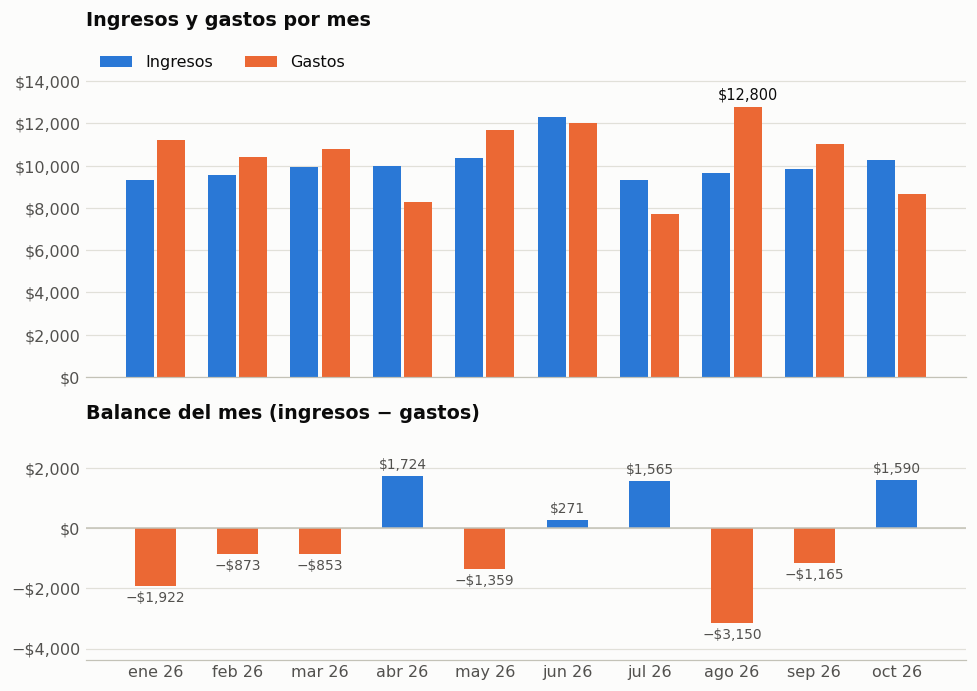

tipo,ingreso,gasto,balance,balance_acumulado
mes,,,,
ene 26,"$9,300","$11,222","−$1,922","−$1,922"
feb 26,"$9,550","$10,423",−$873,"−$2,795"
mar 26,"$9,950","$10,803",−$853,"−$3,648"
abr 26,"$10,000","$8,276","$1,724","−$1,923"
may 26,"$10,350","$11,709","−$1,359","−$3,283"
jun 26,"$12,300","$12,029",$271,"−$3,012"
jul 26,"$9,300","$7,735","$1,565","−$1,446"
ago 26,"$9,650","$12,800","−$3,150","−$4,596"
sep 26,"$9,850","$11,015","−$1,165","−$5,761"


In [6]:
mensual = (df.pivot_table(index="mes", columns="tipo", values="monto", aggfunc="sum", fill_value=0)
             .reindex(columns=["ingreso", "gasto"], fill_value=0))
mensual["balance"] = mensual["ingreso"] - mensual["gasto"]
mensual["balance_acumulado"] = mensual["balance"].cumsum()

etiquetas = [etiqueta_mes(m) for m in mensual.index]
x = np.arange(len(mensual))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.4), sharex=True, height_ratios=[3, 2])

ancho = 0.34
ax1.bar(x - ancho / 2 - 0.02, mensual["ingreso"], ancho, color=AZUL, label="Ingresos")
ax1.bar(x + ancho / 2 + 0.02, mensual["gasto"], ancho, color=NARANJA, label="Gastos")
ax1.set_title("Ingresos y gastos por mes")
ax1.yaxis.set_major_formatter(EJE_PESOS)
ax1.legend(loc="upper left", ncols=2, bbox_to_anchor=(0, 1.02))
ax1.set_ylim(0, mensual[["ingreso", "gasto"]].max().max() * 1.22)
peor = int(mensual["gasto"].to_numpy().argmax())
ax1.annotate(pesos(mensual["gasto"].iloc[peor]), (peor + ancho / 2 + 0.02, mensual["gasto"].iloc[peor]),
             ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9.5, color=TINTA)

ax2.bar(x, mensual["balance"], 0.5, color=[AZUL if v >= 0 else NARANJA for v in mensual["balance"]])
ax2.axhline(0, color=EJE, linewidth=1)
ax2.set_title("Balance del mes (ingresos − gastos)")
ax2.yaxis.set_major_formatter(EJE_PESOS)
for xi, v in zip(x, mensual["balance"]):
    ax2.annotate(pesos(v), (xi, v), ha="center", va="bottom" if v >= 0 else "top",
                 xytext=(0, 3 if v >= 0 else -3), textcoords="offset points", fontsize=9, color=TINTA_2)
ax2.margins(y=0.25)
ax2.set_xticks(x, etiquetas)
fig.tight_layout()
plt.show()

mensual.rename(index=etiqueta_mes).style.format(pesos)

In [7]:
deficit = mensual[mensual["balance"] < 0]
mes_max, mes_min = mensual["gasto"].idxmax(), mensual["gasto"].idxmin()
hallazgo(f'''
En promedio gasto **{pesos(mensual["gasto"].mean())} al mes** y recibo {pesos(mensual["ingreso"].mean())}.
En **{len(deficit)} de {n_meses} meses** gasté más de lo que ingresé; el balance acumulado del periodo es **{pesos(mensual["balance"].sum())}**.
El mes más caro fue **{etiqueta_mes(mes_max)}** ({pesos(mensual.loc[mes_max, "gasto"])}) y el más barato **{etiqueta_mes(mes_min)}** ({pesos(mensual.loc[mes_min, "gasto"])}): una diferencia de {pesos(mensual.loc[mes_max, "gasto"] - mensual.loc[mes_min, "gasto"])} que las siguientes secciones ayudan a explicar.
''')

> **Hallazgo.** En promedio gasto **$10,467 al mes** y recibo $10,050.
> En **6 de 10 meses** gasté más de lo que ingresé; el balance acumulado del periodo es **−$4,171**.
> El mes más caro fue **ago 26** ($12,800) y el más barato **jul 26** ($7,735): una diferencia de $5,065 que las siguientes secciones ayudan a explicar.

## 4. ¿En qué se va el dinero? Gasto por categoría

Saber el total no basta: para decidir dónde recortar hay que ver **la composición**. Se suma el gasto por categoría y se calcula qué porcentaje del total representa cada una. Las barras van ordenadas de mayor a menor para que la comparación sea inmediata.

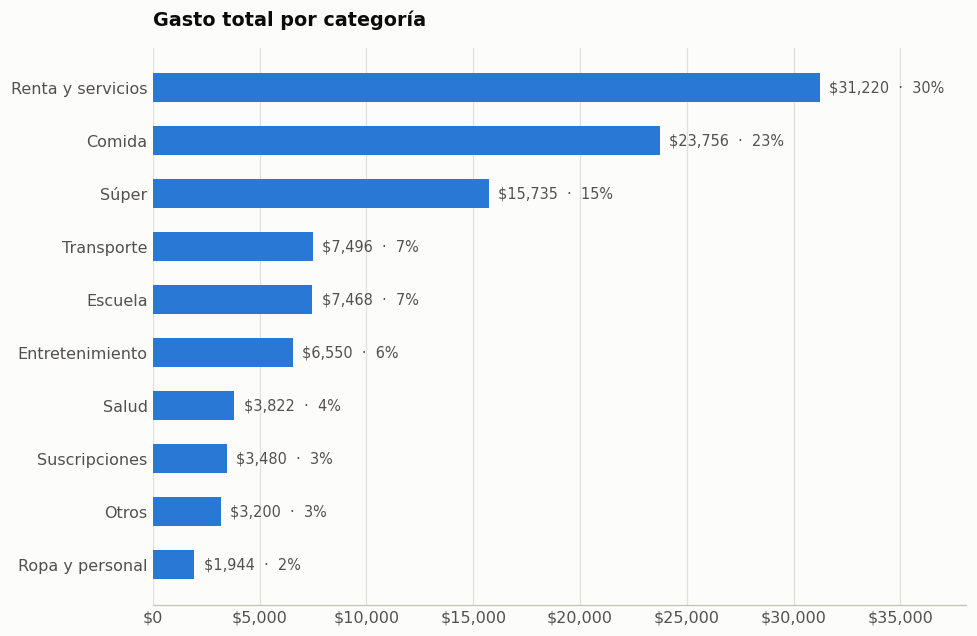

,total,movimientos,ticket_promedio,porcentaje,mensual_promedio
categoria,,,,,
Renta y servicios,"$31,220",25,"$1,249",29.8%,"$3,122"
Comida,"$23,756",262,$91,22.7%,"$2,376"
Súper,"$15,735",39,$403,15.0%,"$1,573"
Transporte,"$7,496",189,$40,7.2%,$750
Escuela,"$7,468",23,$325,7.1%,$747
Entretenimiento,"$6,550",20,$328,6.3%,$655
Salud,"$3,822",6,$637,3.7%,$382
Suscripciones,"$3,480",20,$174,3.3%,$348
Otros,"$3,200",1,"$3,200",3.1%,$320


In [8]:
por_categoria = (gastos.groupby("categoria")["monto"].agg(total="sum", movimientos="size", ticket_promedio="mean")
                       .sort_values("total", ascending=False))
por_categoria["porcentaje"] = por_categoria["total"] / por_categoria["total"].sum()
por_categoria["mensual_promedio"] = por_categoria["total"] / n_meses

orden = por_categoria.index[::-1]
fig, ax = plt.subplots(figsize=(9, 0.46 * len(orden) + 1.3))
y = np.arange(len(orden))
ax.barh(y, por_categoria.loc[orden, "total"], height=0.55, color=AZUL)
ax.set_yticks(y, orden)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(EJE_PESOS)
ax.set_title("Gasto total por categoría")
for yi, cat in zip(y, orden):
    fila = por_categoria.loc[cat]
    ax.annotate(f"{pesos(fila['total'])}  ·  {fila['porcentaje']:.0%}", (fila["total"], yi),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9.5, color=TINTA_2)
ax.set_xlim(0, por_categoria["total"].max() * 1.22)
fig.tight_layout()
plt.show()

por_categoria.style.format({"total": pesos, "ticket_promedio": pesos, "mensual_promedio": pesos, "porcentaje": "{:.1%}"})

### ¿Cambia la composición de un mes a otro?

Un total por categoría puede esconder meses muy distintos entre sí. El siguiente mapa de calor cruza **categoría × mes**: cada celda es el gasto de esa categoría en ese mes, y un azul más oscuro significa más dinero. Sirve para ver de un vistazo qué categorías son estables y cuáles tienen picos.

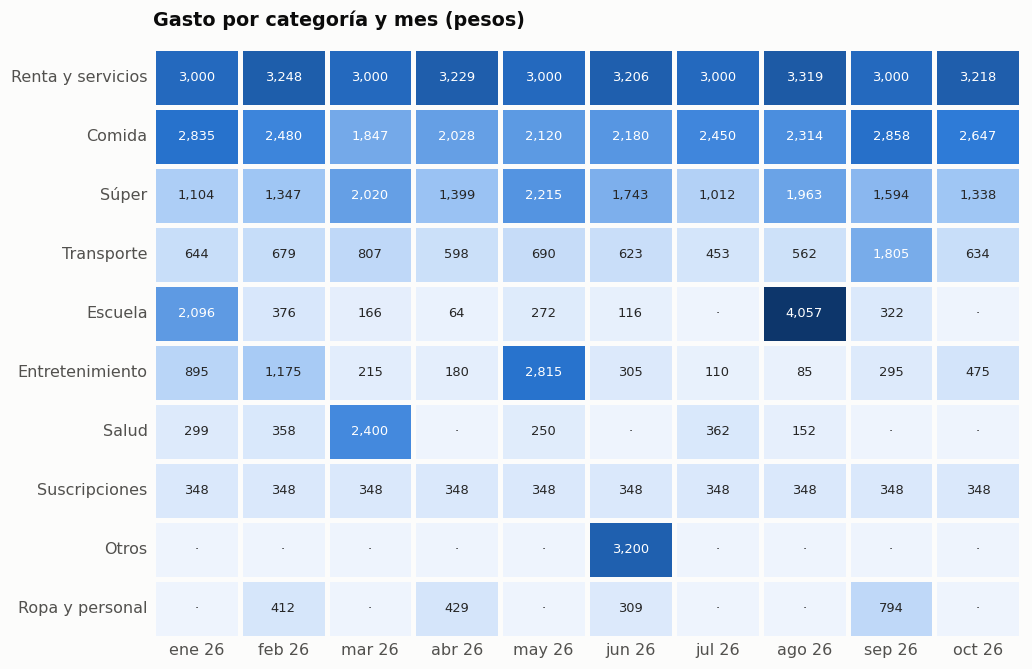

In [9]:
cat_mes = (gastos.pivot_table(index="categoria", columns="mes", values="monto", aggfunc="sum", fill_value=0)
                 .loc[por_categoria.index])
cat_mes.columns = [etiqueta_mes(m) for m in cat_mes.columns]

fig, ax = plt.subplots(figsize=(9.5, 0.5 * len(cat_mes) + 1.2))
sns.heatmap(cat_mes, ax=ax, cmap=ESCALA_AZUL, linewidths=2, linecolor=FONDO, cbar=False,
            annot=cat_mes.map(lambda v: f"{v:,.0f}" if v else "·"), fmt="",
            annot_kws={"fontsize": 8.5})
ax.set_title("Gasto por categoría y mes (pesos)")
ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False); ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

In [10]:
top3 = por_categoria.head(3)
variacion = (cat_mes.std(axis=1) / cat_mes.mean(axis=1)).sort_values()
pico_cat = cat_mes.stack().idxmax()
hallazgo(f'''
Tres categorías concentran el **{top3["porcentaje"].sum():.0%}** del gasto: {", ".join(f"**{c}** ({f.porcentaje:.0%})" for c, f in top3.iterrows())}.
La más estable de un mes a otro es *{variacion.index[0]}* y la más irregular es *{variacion.index[-1]}*.
El mayor gasto de una sola categoría en un mes fue **{pico_cat[0]}** en **{pico_cat[1]}** ({pesos(cat_mes.stack().max())}).
La categoría con más movimientos es *{por_categoria["movimientos"].idxmax()}* ({por_categoria["movimientos"].max()} compras, ticket promedio de {pesos(por_categoria.loc[por_categoria["movimientos"].idxmax(), "ticket_promedio"])}): son muchos gastos pequeños, de los que más cuesta llevar la cuenta.
''')

> **Hallazgo.** Tres categorías concentran el **68%** del gasto: **Renta y servicios** (30%), **Comida** (23%), **Súper** (15%).
> La más estable de un mes a otro es *Suscripciones* y la más irregular es *Otros*.
> El mayor gasto de una sola categoría en un mes fue **Escuela** en **ago 26** ($4,057).
> La categoría con más movimientos es *Comida* (262 compras, ticket promedio de $91): son muchos gastos pequeños, de los que más cuesta llevar la cuenta.

## 5. Patrones por día de la semana

¿Gasto igual un martes que un sábado? Para compararlos con justicia no basta sumar por día de la semana, por dos razones:

- **Los gastos fijos distorsionan.** La renta cae en la fecha que toque; si un mes cae en lunes, "inflaría" los lunes sin que eso diga nada de mis hábitos. Por eso aquí se excluyen las categorías de gasto fijo y los gastos mayores a un umbral (se analizan aparte, en las secciones 6 y 7).
- **Hay que contar los días sin gasto.** Se calcula el gasto de *cada día del calendario* (con cero si no hubo nada) y luego se promedia por día de la semana.

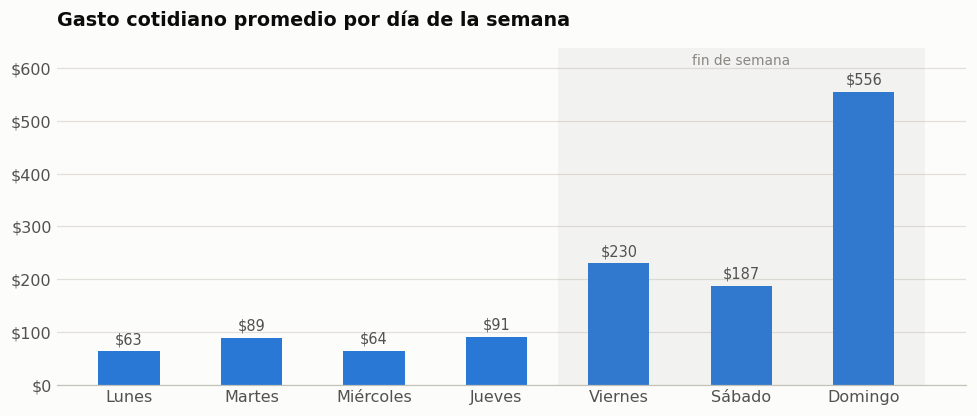

,gasto_promedio,compras_promedio
Lunes,$63,1.40
Martes,$89,1.51
Miércoles,$64,1.35
Jueves,$91,1.61
Viernes,$230,2.36
Sábado,$187,1.66
Domingo,$556,2.47


In [11]:
FIJAS = ["Renta y servicios", "Suscripciones"]
umbral_grande = gastos["monto"].quantile(0.97)
cotidiano = gastos[~gastos["categoria"].isin(FIJAS) & (gastos["monto"] <= umbral_grande)]

calendario = pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="D")
diario = cotidiano.groupby("fecha")["monto"].sum().reindex(calendario, fill_value=0)
por_dia = pd.DataFrame({
    "gasto_promedio": diario.groupby(diario.index.dayofweek).mean(),
    "compras_promedio": cotidiano.groupby("fecha").size().reindex(calendario, fill_value=0)
                                 .groupby(calendario.dayofweek).mean(),
})
por_dia.index = DIAS

fig, ax = plt.subplots(figsize=(9, 3.9))
x = np.arange(7)
ax.bar(x, por_dia["gasto_promedio"], 0.5, color=AZUL)
ax.set_xticks(x, [d.capitalize() for d in DIAS])
ax.yaxis.set_major_formatter(EJE_PESOS)
ax.set_title("Gasto cotidiano promedio por día de la semana")
for xi, v in zip(x, por_dia["gasto_promedio"]):
    ax.annotate(pesos(v), (xi, v), ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                fontsize=9.5, color=TINTA_2)
ax.set_ylim(0, por_dia["gasto_promedio"].max() * 1.15)
ax.axvspan(3.5, 6.5, color=TENUE, alpha=0.08, linewidth=0)
ax.text(5, por_dia["gasto_promedio"].max() * 1.09, "fin de semana", ha="center", fontsize=9, color=TENUE)
fig.tight_layout()
plt.show()

por_dia.rename(index=str.capitalize).style.format({"gasto_promedio": pesos, "compras_promedio": "{:.2f}"})

In [12]:
entre_semana, finde = por_dia["gasto_promedio"].iloc[:4].mean(), por_dia["gasto_promedio"].iloc[4:].mean()
# Solo categorías con suficientes compras: con pocas, la comparación sería ruido.
frecuentes = cotidiano["categoria"].value_counts().loc[lambda s: s >= 20].index
cat_finde = (cotidiano[cotidiano["categoria"].isin(frecuentes)]
             .groupby(["categoria", "fin_de_semana"])["monto"].sum().unstack(fill_value=0))
cat_finde = (cat_finde[True] / 3) / (cat_finde[False] / 4).replace(0, np.nan)   # por día: 3 días contra 4
dia_pico = por_dia["gasto_promedio"].idxmax()
motor = cotidiano[cotidiano["dia_semana"] == dia_pico].groupby("categoria")["monto"].sum()
hallazgo(f'''
El día más caro es el **{dia_pico}** ({pesos(por_dia["gasto_promedio"].max())} en promedio), impulsado por *{motor.idxmax()}* ({motor.max() / motor.sum():.0%} de lo gastado ese día); el más barato es el **{por_dia["gasto_promedio"].idxmin()}** ({pesos(por_dia["gasto_promedio"].min())}).
De viernes a domingo gasto **{pesos(finde)} por día**, contra {pesos(entre_semana)} de lunes a jueves: **{finde / entre_semana:.1f} veces más**.
Entre las categorías frecuentes, la que más crece en fin de semana es *{cat_finde.idxmax()}* ({cat_finde.max():.1f}× por día). Si quisiera recortar gastos, el fin de semana es donde un presupuesto tendría más efecto.
''')

> **Hallazgo.** El día más caro es el **domingo** ($556 en promedio), impulsado por *Súper* (66% de lo gastado ese día); el más barato es el **lunes** ($63).
> De viernes a domingo gasto **$324 por día**, contra $77 de lunes a jueves: **4.2 veces más**.
> Entre las categorías frecuentes, la que más crece en fin de semana es *Comida* (2.5× por día). Si quisiera recortar gastos, el fin de semana es donde un presupuesto tendría más efecto.

## 6. Gastos recurrentes: mi costo fijo mensual

Un gasto **recurrente** es el que se repite cada mes por un monto parecido: renta, suscripciones, plan de celular. Conviene identificarlos porque son el "piso" del gasto: se pagan aunque no haga nada más, y a menudo incluyen suscripciones olvidadas.

No hay una columna que diga "esto es recurrente", así que se **detecta con reglas** sobre el comportamiento de cada descripción. Un gasto se considera recurrente si cumple las cuatro:

| Regla | Criterio | Por qué |
|---|---|---|
| Presencia | aparece en al menos el 60 % de los meses | se repite de forma sostenida |
| Frecuencia | como máximo una vez por mes, en promedio | descarta compras habituales (tacos, café) |
| Monto estable | coeficiente de variación menor a 15 % | el cobro es prácticamente el mismo |
| Fecha estable | el día del mes varía 3 días o menos | cae en la misma fecha |

El *coeficiente de variación* es la desviación estándar dividida entre la media: mide qué tanto cambia el monto en proporción a su tamaño.

In [13]:
con_texto = gastos[gastos["descripcion"] != "Sin descripción"].assign(
    clave=lambda d: d["descripcion"].str.casefold().str.replace(r"\d+", "", regex=True).str.strip(),
    dia=lambda d: d["fecha"].dt.day,
)
perfil = con_texto.groupby("clave").agg(
    descripcion=("descripcion", "first"), categoria=("categoria", "first"),
    meses=("mes", "nunique"), veces=("monto", "size"),
    monto_tipico=("monto", "median"),
    variacion=("monto", lambda s: s.std(ddof=0) / s.mean()),
    dia_tipico=("dia", "median"), dia_desv=("dia", lambda s: s.std(ddof=0)),
)
es_recurrente = (
    (perfil["meses"] >= 0.6 * n_meses) & (perfil["veces"] <= perfil["meses"] * 1.2)
    & (perfil["variacion"] < 0.15) & (perfil["dia_desv"] <= 3)
)
recurrentes = perfil[es_recurrente].sort_values("monto_tipico", ascending=False)
costo_fijo = recurrentes["monto_tipico"].sum()

(recurrentes[["descripcion", "categoria", "meses", "monto_tipico", "dia_tipico"]]
    .rename(columns={"descripcion": "Gasto", "categoria": "Categoría", "meses": "Meses presentes",
                     "monto_tipico": "Monto típico", "dia_tipico": "Día del mes"})
    .style.format({"Monto típico": pesos, "Día del mes": "{:.0f}"}).hide(axis="index"))

Gasto,Categoría,Meses presentes,Monto típico,Día del mes
Renta del cuarto,Renta y servicios,9,"$2,800",5
NETFLIX,Suscripciones,10,$219,12
Recarga TELCEL,Renta y servicios,10,$200,20
SPOTIFY MEXICO,Suscripciones,10,$129,6


In [14]:
if recurrentes.empty:
    hallazgo("Con estas reglas no se detectó ningún gasto recurrente. Con pocos meses de historial es normal: la regla de presencia necesita al menos tres o cuatro meses.")
else:
    mayor = recurrentes.iloc[0]
    subs = recurrentes[recurrentes["categoria"] == "Suscripciones"]
    hallazgo(f'''
Se detectaron **{len(recurrentes)} gastos recurrentes** que suman **{pesos(costo_fijo)} al mes**: el **{costo_fijo / mensual["gasto"].mean():.0%}** de mi gasto mensual promedio es fijo antes de comprar nada más.
El mayor es *{mayor["descripcion"]}* ({pesos(mayor["monto_tipico"])}, alrededor del día {mayor["dia_tipico"]:.0f}).
Las suscripciones detectadas suman {pesos(subs["monto_tipico"].sum())} al mes, es decir **{pesos(subs["monto_tipico"].sum() * 12)} al año**.
*Limitación:* la detección depende de que la descripción se repita igual. Pagos bimestrales o con texto variable (como los que escribe el banco) pueden no detectarse.
''')

> **Hallazgo.** Se detectaron **4 gastos recurrentes** que suman **$3,348 al mes**: el **32%** de mi gasto mensual promedio es fijo antes de comprar nada más.
> El mayor es *Renta del cuarto* ($2,800, alrededor del día 5).
> Las suscripciones detectadas suman $348 al mes, es decir **$4,176 al año**.
> *Limitación:* la detección depende de que la descripción se repita igual. Pagos bimestrales o con texto variable (como los que escribe el banco) pueden no detectarse.

## 7. Gastos atípicos

Un gasto **atípico** es el que se sale de lo normal: una emergencia, una compra grande o un posible error de captura. Vale la pena encontrarlos por dos motivos: explican los meses caros y, si no se separan, distorsionan los promedios y cualquier proyección.

**Método: rango intercuartílico (IQR) por categoría, en escala logarítmica.** Para cada categoría se calculan el cuartil 1 (Q1) y el cuartil 3 (Q3) del *logaritmo* de sus montos; el IQR es Q3 − Q1. El límite de la categoría es:

$$\text{límite} = \exp\left(Q_3 + 1.5 \times IQR\right)$$

Un gasto se marca como atípico si cumple **tres condiciones**: supera el límite de su categoría, no es un gasto recurrente (sección 6), y es **relevante** (al menos el 5 % del gasto mensual promedio). Las decisiones detrás:

- **Por categoría y no sobre todos los gastos juntos.** $2,800 es normal para la renta, pero sería rarísimo en comida. Un único límite global marcaría la renta cada mes y dejaría pasar una comida de $900. Las categorías con menos de 8 gastos no tienen datos suficientes para un límite propio, así que usan el límite general.
- **IQR en lugar de "media ± 3 desviaciones estándar".** La media y la desviación se ven arrastradas por los propios valores extremos que se quieren detectar; los cuartiles no.
- **Escala logarítmica.** Los montos son muy asimétricos: muchos gastos chicos y pocos grandes. Sin el logaritmo, la regla marcaría como "atípica" cualquier comida algo más cara de lo habitual (en una primera versión señalaba más del 10 % de los gastos). En logaritmos la pregunta pasa a ser *cuántas veces más grande* es un gasto, que es lo que importa.
- **Relevancia.** Un pasaje de $60 puede ser raro frente a los de $12, pero no cambia el mes. El filtro deja solo lo que de verdad mueve el presupuesto.

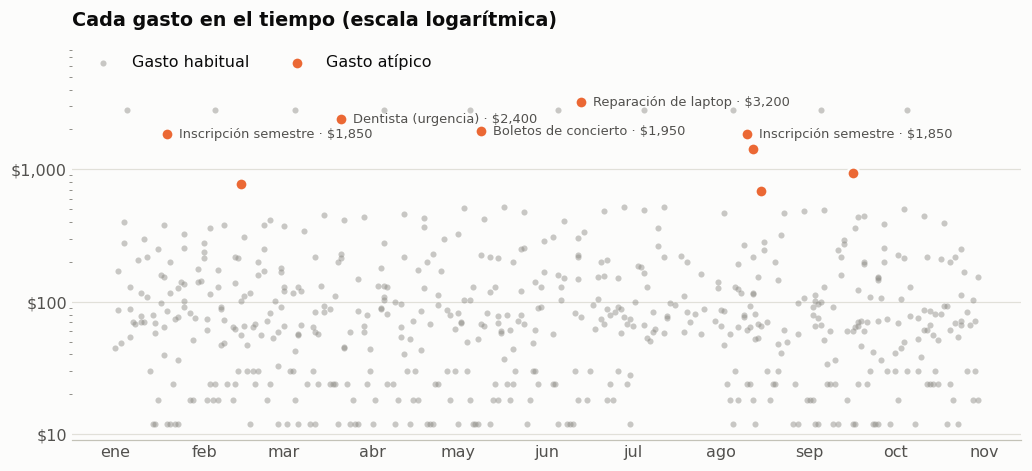

Fecha,Categoría,Descripción,Monto,Límite de su categoría
13/06/2026,Otros,Reparación de laptop,"$3,200","$1,082"
21/03/2026,Salud,Dentista (urgencia),"$2,400","$1,082"
09/05/2026,Entretenimiento,Boletos de concierto,"$1,950",$561
19/01/2026,Escuela,Inscripción semestre,"$1,850",$496
10/08/2026,Escuela,Inscripción semestre,"$1,850",$496
12/08/2026,Escuela,Libros del semestre,"$1,420",$496
16/09/2026,Transporte,Autobús a casa (puente),$940,$119
14/02/2026,Entretenimiento,Cena de San Valentín,$780,$561
15/08/2026,Escuela,Calculadora científica,$690,$496


In [15]:
MINIMO = 8                                   # gastos mínimos para que una categoría tenga límite propio
RELEVANTE = 0.05 * mensual["gasto"].mean()   # 5 % del gasto mensual promedio


def limite_log(montos):
    q1, q3 = np.log(montos).quantile([0.25, 0.75])
    return float(np.exp(q3 + 1.5 * (q3 - q1)))


clave_gasto = gastos["descripcion"].str.casefold().str.replace(r"\d+", "", regex=True).str.strip()
gastos["recurrente"] = clave_gasto.isin(recurrentes.index)
# Un cobro sin descripción que coincide con un recurrente en categoría, monto (±2 %)
# y día del mes (±3) es ese mismo recurrente: la limpieza no debe volverlo "atípico".
for _, r in recurrentes.iterrows():
    gastos["recurrente"] |= (
        (gastos["categoria"] == r["categoria"])
        & ((gastos["monto"] - r["monto_tipico"]).abs() <= 0.02 * r["monto_tipico"])
        & ((gastos["fecha"].dt.day - r["dia_tipico"]).abs() <= 3)
    )
candidatos = gastos[~gastos["recurrente"]]

limite_general = limite_log(candidatos["monto"])
limites = candidatos.groupby("categoria")["monto"].agg(n="size", limite=limite_log)
limites.loc[limites["n"] < MINIMO, "limite"] = limite_general

gastos["limite"] = gastos["categoria"].map(limites["limite"]).fillna(limite_general)
gastos["atipico"] = ~gastos["recurrente"] & (gastos["monto"] > gastos["limite"]) & (gastos["monto"] >= RELEVANTE)
atipicos = gastos[gastos["atipico"]].sort_values("monto", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
normales = gastos[~gastos["atipico"]]
ax.scatter(normales["fecha"], normales["monto"], s=16, color=TENUE, alpha=0.45, linewidths=0, label="Gasto habitual")
ax.scatter(atipicos["fecha"], atipicos["monto"], s=62, color=NARANJA, edgecolors=FONDO, linewidths=1.5,
           label="Gasto atípico", zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(EJE_PESOS)
ax.set_title("Cada gasto en el tiempo (escala logarítmica)")
ax.legend(loc="upper left", ncols=2, bbox_to_anchor=(0, 1.02))
# Se rotulan solo los cinco mayores: un rótulo en cada punto sería ilegible.
for _, fila in atipicos.head(5).iterrows():
    ax.annotate(f"{fila['descripcion']} · {pesos(fila['monto'])}", (fila["fecha"], fila["monto"]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=TINTA_2)
ax.set_ylim(top=gastos["monto"].max() * 2.6)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: MESES[plt.matplotlib.dates.num2date(v).month - 1]))
fig.tight_layout()
plt.show()

(atipicos[["fecha", "categoria", "descripcion", "monto", "limite"]].head(15)
    .rename(columns={"fecha": "Fecha", "categoria": "Categoría", "descripcion": "Descripción",
                     "monto": "Monto", "limite": "Límite de su categoría"})
    .style.format({"Fecha": "{:%d/%m/%Y}", "Monto": pesos, "Límite de su categoría": pesos}).hide(axis="index"))

La escala del eje vertical es **logarítmica**: cada marca representa diez veces más que la anterior. Se usa porque los gastos van de unos $12 a varios miles; en una escala normal los pequeños quedarían aplastados contra el eje. Nótese que hay puntos grises (habituales) *más altos* que algunos naranjas: es la renta, que es grande pero recurrente y perfectamente normal dentro de su categoría.

In [16]:
por_mes_atip = atipicos.groupby("mes")["monto"].sum().reindex(mensual.index, fill_value=0)
mes_top = por_mes_atip.idxmax()
hallazgo(f'''
Se detectaron **{len(atipicos)} gastos atípicos**: apenas el {len(atipicos) / len(gastos):.1%} de los movimientos, pero suman **{pesos(atipicos["monto"].sum())}**, el **{atipicos["monto"].sum() / gastos["monto"].sum():.0%}** de todo el gasto.
El mayor fue *{atipicos.iloc[0]["descripcion"]}* ({pesos(atipicos.iloc[0]["monto"])}, {atipicos.iloc[0]["categoria"]}).
El mes con más gasto atípico fue **{etiqueta_mes(mes_top)}** ({pesos(por_mes_atip.max())}), {"que es también el mes más caro del periodo: los atípicos explican el pico" if mes_top == mes_max else f"mientras que el mes más caro fue {etiqueta_mes(mes_max)}"}.
Atípico no significa "malo": varios son gastos necesarios (escuela, salud). La utilidad es **anticiparlos**: si se repiten cada semestre o cada año, conviene apartar dinero antes.
''')

> **Hallazgo.** Se detectaron **9 gastos atípicos**: apenas el 1.5% de los movimientos, pero suman **$15,080**, el **14%** de todo el gasto.
> El mayor fue *Reparación de laptop* ($3,200, Otros).
> El mes con más gasto atípico fue **ago 26** ($3,960), que es también el mes más caro del periodo: los atípicos explican el pico.
> Atípico no significa "malo": varios son gastos necesarios (escuela, salud). La utilidad es **anticiparlos**: si se repiten cada semestre o cada año, conviene apartar dinero antes.

## 8. Proyección del gasto del próximo mes

Con el historial mensual se puede estimar cuánto gastaré el mes siguiente. Hay muy pocos datos (un punto por mes), así que no tiene sentido un modelo complejo: se comparan **cuatro métodos simples** y se elige el que mejor haya funcionado *en el pasado*.

| Método | Idea |
|---|---|
| **Último mes** | El próximo mes será igual al anterior. Es la referencia mínima: si un método no le gana, no sirve. |
| **Promedio histórico** | El promedio de todos los meses anteriores. |
| **Promedio móvil (3 meses)** | El promedio de los tres meses más recientes; se adapta si mis hábitos cambian. |
| **Tendencia lineal** | Una recta ajustada a los meses anteriores (regresión lineal), extendida un mes. |

**¿Cómo se comparan? Con validación hacia adelante (*walk-forward*).** Para cada mes a partir del cuarto, se "esconde" ese mes y los posteriores, se predice usando solo los meses previos y se compara con lo que realmente pasó. Así se imita la situación real: predecir el futuro sin haberlo visto. El error se resume con el **MAE** (error absoluto medio): en promedio, por cuántos pesos falla cada método.

Si los datos terminan a mitad de un mes, ese mes incompleto se excluye para no confundir "mes barato" con "mes sin terminar".

In [17]:
serie = mensual["gasto"].copy()
ultimo_dia = df["fecha"].max()
if ultimo_dia.day < ultimo_dia.days_in_month - 2:      # el último mes está incompleto
    print(f"Se excluye {etiqueta_mes(serie.index[-1])} por estar incompleto (datos hasta el día {ultimo_dia.day}).")
    serie = serie.iloc[:-1]

METODOS = {
    "Último mes": lambda h: h[-1],
    "Promedio histórico": lambda h: h.mean(),
    "Promedio móvil (3 meses)": lambda h: h[-3:].mean(),
    "Tendencia lineal": lambda h: np.polyval(np.polyfit(np.arange(len(h)), h, 1), len(h)),
}

valores = serie.to_numpy()
INICIO = 3   # se necesitan al menos 3 meses de historia para predecir el cuarto
if len(valores) <= INICIO:
    raise SystemExit("Se necesitan al menos 4 meses completos de datos para evaluar una proyección.")

pruebas = pd.DataFrame(
    {nombre: [f(valores[:i]) for i in range(INICIO, len(valores))] for nombre, f in METODOS.items()},
    index=serie.index[INICIO:])
errores = pruebas.sub(serie.iloc[INICIO:], axis=0).abs()
evaluacion = pd.DataFrame({
    "MAE (pesos)": errores.mean(),
    "Error relativo": errores.div(serie.iloc[INICIO:], axis=0).mean(),
    "Proyección próximo mes": {nombre: f(valores) for nombre, f in METODOS.items()},
}).sort_values("MAE (pesos)")
mejor = evaluacion.index[0]
proyeccion, margen = evaluacion.loc[mejor, "Proyección próximo mes"], evaluacion.loc[mejor, "MAE (pesos)"]

evaluacion.style.format({"MAE (pesos)": pesos, "Error relativo": "{:.1%}", "Proyección próximo mes": pesos})

,MAE (pesos),Error relativo,Proyección próximo mes
Promedio móvil (3 meses),"$1,921",20.0%,"$10,825"
Promedio histórico,"$1,929",20.2%,"$10,467"
Tendencia lineal,"$2,438",24.7%,"$10,126"
Último mes,"$2,826",28.7%,"$8,660"


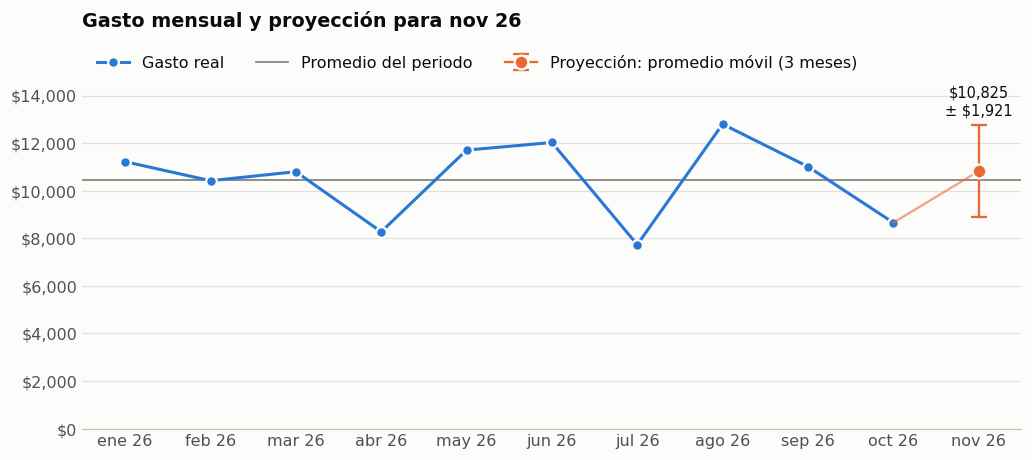

In [18]:
proximo = serie.index[-1] + 1
x = np.arange(len(serie))
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(x, serie.values, color=AZUL, linewidth=2, marker="o", markersize=7,
        markeredgecolor=FONDO, markeredgewidth=1.5, label="Gasto real")
ax.plot([x[-1], x[-1] + 1], [serie.values[-1], proyeccion], color=NARANJA, linewidth=1.5, alpha=0.6)
ax.errorbar(x[-1] + 1, proyeccion, yerr=margen, color=NARANJA, marker="o", markersize=9,
            markeredgecolor=FONDO, markeredgewidth=1.5, capsize=5, linewidth=1.5,
            label=f"Proyección: {mejor.lower()}")
ax.axhline(serie.mean(), color=TENUE, linewidth=1.2, label="Promedio del periodo", zorder=1)
ax.annotate(f"{pesos(proyeccion)}\n± {pesos(margen)}", (x[-1] + 1, proyeccion + margen), ha="center", va="bottom",
            xytext=(0, 5), textcoords="offset points", fontsize=9.5, color=TINTA)
ax.set_xticks(list(x) + [x[-1] + 1], [etiqueta_mes(m) for m in serie.index] + [etiqueta_mes(proximo)])
ax.set_xlim(-0.5, x[-1] + 1.5)
ax.yaxis.set_major_formatter(EJE_PESOS)
ax.set_ylim(0, max(serie.max(), proyeccion + margen) * 1.25)
ax.set_title(f"Gasto mensual y proyección para {etiqueta_mes(proximo)}")
ax.legend(loc="upper left", ncols=3, bbox_to_anchor=(0, 1.02))
fig.tight_layout()
plt.show()

### Una segunda estimación: costo fijo + gasto variable

Los métodos anteriores tratan al mes como un solo número. Otra forma de estimar aprovecha lo aprendido en las secciones 6 y 7 y arma el mes por partes:

$$\text{gasto esperado} = \underbrace{\text{recurrentes}}_{\text{se conocen de antemano}} + \underbrace{\text{mediana del gasto variable habitual}}_{\text{sin atípicos}}$$

Se usa la **mediana** y no el promedio del gasto variable porque la mediana no se deja arrastrar por un mes excepcional. Esta estimación representa un **mes normal, sin imprevistos**, así que sirve como base para un presupuesto.

In [19]:
variable = gastos[~gastos["atipico"] & ~gastos["recurrente"]]
variable_mensual = variable.groupby("mes")["monto"].sum().reindex(serie.index, fill_value=0)
mes_normal = costo_fijo + variable_mensual.median()
atipico_mensual = atipicos["monto"].sum() / n_meses

hallazgo(f'''
El método con menor error histórico es **{mejor.lower()}**, que falla en promedio por {pesos(margen)} ({evaluacion.loc[mejor, "Error relativo"]:.0%}). Con él, la proyección para **{etiqueta_mes(proximo)}** es de **{pesos(proyeccion)}**, con un rango razonable de {pesos(proyeccion - margen)} a {pesos(proyeccion + margen)}.
Armando el mes por partes, un mes normal cuesta **{pesos(mes_normal)}**: {pesos(costo_fijo)} de gastos fijos más {pesos(variable_mensual.median())} de gasto variable habitual.
La diferencia entre ambas cifras se explica por los imprevistos, que promedian **{pesos(atipico_mensual)} al mes**. Un presupuesto realista sería entonces el mes normal más una reserva de ese tamaño.
''')

> **Hallazgo.** El método con menor error histórico es **promedio móvil (3 meses)**, que falla en promedio por $1,921 (20%). Con él, la proyección para **nov 26** es de **$10,825**, con un rango razonable de $8,904 a $12,745.
> Armando el mes por partes, un mes normal cuesta **$8,834**: $3,348 de gastos fijos más $5,486 de gasto variable habitual.
> La diferencia entre ambas cifras se explica por los imprevistos, que promedian **$1,508 al mes**. Un presupuesto realista sería entonces el mes normal más una reserva de ese tamaño.

### Limitaciones de la proyección

Es importante ser honesta con lo que este modelo **no** puede hacer:

- **Pocos datos.** Con alrededor de diez puntos, el error estimado (MAE) es apenas una orientación; un mes inusual cambia el resultado.
- **No modela estacionalidad.** El gasto escolar se repite cada semestre, pero para que un modelo lo aprenda necesitaría ver varios ciclos (al menos dos años).
- **El rango no es un intervalo de confianza formal.** "± MAE" resume el error típico del pasado; no garantiza que el valor real caiga dentro.
- **Supone que mis hábitos no cambian.** Una mudanza, un nuevo ingreso o un cambio de precios invalida la proyección.

Por eso, en este problema un método sencillo y explicable es preferible a uno sofisticado: es más fácil saber cuándo dejar de confiar en él.

## 9. Conclusiones

La siguiente celda reúne las cifras principales del análisis, respondiendo a las cinco preguntas del inicio.

In [20]:
display(Markdown(f'''
| Pregunta | Respuesta |
|---|---|
| **1. ¿Cuánto gasto y cuánto me queda?** | Gasto {pesos(mensual["gasto"].mean())} al mes en promedio; en {len(deficit)} de {n_meses} meses gasté más de lo que ingresé. Balance del periodo: {pesos(mensual["balance"].sum())}. |
| **2. ¿En qué se concentra?** | {", ".join(top3.index)} suman el {top3["porcentaje"].sum():.0%} del gasto. |
| **3. ¿Cambia según el día?** | De viernes a domingo gasto {finde / entre_semana:.1f} veces más por día que de lunes a jueves. |
| **4. ¿Qué es fijo y qué es atípico?** | {len(recurrentes)} gastos recurrentes suman {pesos(costo_fijo)} al mes ({costo_fijo / mensual["gasto"].mean():.0%} del gasto). {len(atipicos)} gastos atípicos explican el {atipicos["monto"].sum() / gastos["monto"].sum():.0%} del gasto total. |
| **5. ¿Qué espero el próximo mes?** | Alrededor de {pesos(proyeccion)} (entre {pesos(proyeccion - margen)} y {pesos(proyeccion + margen)}). Un mes sin imprevistos cuesta {pesos(mes_normal)}. |
'''))


| Pregunta | Respuesta |
|---|---|
| **1. ¿Cuánto gasto y cuánto me queda?** | Gasto $10,467 al mes en promedio; en 6 de 10 meses gasté más de lo que ingresé. Balance del periodo: −$4,171. |
| **2. ¿En qué se concentra?** | Renta y servicios, Comida, Súper suman el 68% del gasto. |
| **3. ¿Cambia según el día?** | De viernes a domingo gasto 4.2 veces más por día que de lunes a jueves. |
| **4. ¿Qué es fijo y qué es atípico?** | 4 gastos recurrentes suman $3,348 al mes (32% del gasto). 9 gastos atípicos explican el 14% del gasto total. |
| **5. ¿Qué espero el próximo mes?** | Alrededor de $10,825 (entre $8,904 y $12,745). Un mes sin imprevistos cuesta $8,834. |


### Qué haría con estos resultados

- **Presupuesto en dos partes.** Separar el costo fijo (que no depende de mis decisiones del día a día) del gasto variable, y fijar la meta solo sobre el segundo.
- **Atención al fin de semana.** Es donde el gasto diario se dispara; un tope semanal para comida fuera y entretenimiento atacaría la parte más flexible del gasto.
- **Fondo para imprevistos.** Los gastos atípicos no son predecibles uno por uno, pero su promedio mensual sí: apartar esa cantidad cada mes amortigua los meses en déficit.
- **Revisar las suscripciones** una vez al año, ahora que se sabe cuánto cuestan en conjunto.

### Siguientes pasos del proyecto

- Acumular más meses para poder modelar la **estacionalidad** (inicio de semestre, vacaciones, diciembre).
- Mejorar la detección de recurrentes con el **folio y el comercio** del estado de cuenta, en vez de la descripción exacta.
- Añadir **presupuestos por categoría** en la app y comparar lo planeado contra lo real.

---
*Notebook reproducible: con `FUENTE = "ejemplo"` cualquiera puede ejecutarlo de principio a fin y obtener exactamente estas cifras.*